# Evasion attacks on an ML intrusion detector
**Data:** CIC-IDS-2017, Friday-afternoon DDoS file (benign vs DDoS flows).
**Question:** if an attacker can query the detector, how often can they make a DDoS flow look benign, and does adversarial training help?

Built on top of the open-source [xai-ids](https://github.com/MohammadThabetHassan/xai-ids) project (credit to its authors). The original repo's FGSM test does not work on tree models; this notebook uses a black-box attack instead.

In [1]:
import sys, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix
from xgboost import XGBClassifier
warnings.filterwarnings("ignore")

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)

SEED = 42
N_ATTACK = 100       # test flows to attack (raise for tighter estimates, costs time)
N_ADV_TRAIN = 200    # training flows to turn into adversarial examples for the defense
N_FEATURES = 20      # keep the 20 most important features
rng = np.random.RandomState(SEED)

## 1. Load and clean
Strip column names, drop infinities/NaNs, and **drop duplicate flows** (duplicates can leak between train and test and inflate accuracy).

In [2]:
csv_files = sorted((ROOT / "data" / "raw").glob("*.csv"))
assert csv_files, "Put the CIC-IDS-2017 CSV in data/raw/"
CSV = csv_files[0]
print("Using:", CSV.name)

df = pd.read_csv(CSV, encoding="latin1", low_memory=False)
df.columns = df.columns.str.strip()
n_raw = len(df)
df = df.replace([np.inf, -np.inf], np.nan).dropna().drop_duplicates()
print(f"rows: {n_raw} -> {len(df)} after cleaning and de-duplication")

y = (df["Label"].astype(str).str.strip().str.upper() != "BENIGN").astype(int).values  # 1 = attack
X = df.drop(columns=["Label"]).select_dtypes(include=[np.number])
X = X.loc[:, X.nunique() > 1]  # drop constant columns
print("features:", X.shape[1], "| attack share:", round(y.mean(), 3))

Using: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
rows: 225745 -> 223082 after cleaning and de-duplication
features: 68 | attack share: 0.574


## 2. Split, scale, train a baseline detector
Seeded stratified split. Scaling (RobustScaler) puts features on comparable scales, which makes attack perturbation sizes meaningful.

In [3]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=SEED)
scaler = RobustScaler().fit(Xtr)
Xtr_s, Xte_s = scaler.transform(Xtr), scaler.transform(Xte)

XGB_PARAMS = dict(n_estimators=200, max_depth=6, learning_rate=0.1, n_jobs=-1,
                  eval_metric="logloss", random_state=SEED)

# keep the most important features (fewer dimensions = cheaper, clearer attack)
base = XGBClassifier(**XGB_PARAMS).fit(Xtr_s, ytr)
top = np.argsort(base.feature_importances_)[::-1][:N_FEATURES]
feat_names = list(X.columns[top])
Xtr20, Xte20 = Xtr_s[:, top].astype(np.float32), Xte_s[:, top].astype(np.float32)

model = XGBClassifier(**XGB_PARAMS).fit(Xtr20, ytr)
pred = model.predict(Xte20)
base_acc = accuracy_score(yte, pred)
base_recall = recall_score(yte, pred)
print("top features:", feat_names[:8], "...")
print(f"BASELINE  accuracy={base_acc:.4f}  attack recall={base_recall:.4f}")
print(confusion_matrix(yte, pred))

top features: ['Fwd Packet Length Max', 'Total Length of Fwd Packets', 'Fwd Packet Length Mean', 'Bwd Packet Length Mean', 'Total Fwd Packets', 'Init_Win_bytes_forward', 'Bwd Header Length', 'Bwd IAT Total'] ...
BASELINE  accuracy=1.0000  attack recall=0.9999
[[28520     1]
 [    2 38402]]


## 3. Why the original repo's FGSM test does not work here
FGSM needs gradients of the model's loss. Gradient-boosted trees are piecewise constant, so they have none. The repo's `evaluate_adversarial_robustness` wraps the model in ART's FGSM, which only works for differentiable models, so on XGBoost it returns an error that the pipeline then silently skips.

In [4]:
try:
    from src.evaluation.adversarial import evaluate_adversarial_robustness
    out = evaluate_adversarial_robustness(model, Xte20[:500], yte[:500])
    print("Repo FGSM result on XGBoost ->", {k: v for k, v in out.items() if k != "adversarial_samples"})
except Exception as e:
    print("Repo FGSM call raised:", type(e).__name__, e)

2026-11-13 07:53:11 | xai_ids.evaluation.adversarial | WARNING  | ART FGSM attack failed (model may not support gradients): Model is not an sklearn model. Received '<class 'xgboost.sklearn.XGBClassifier'>'


Repo FGSM result on XGBoost -> {'error': "ART FGSM not supported for this model: Model is not an sklearn model. Received '<class 'xgboost.sklearn.XGBClassifier'>'", 'epsilons': [0.01, 0.05, 0.1]}


## 4. Black-box evasion attack (HopSkipJump)
The attacker can only **query** the detector (get its output) and tries to find a nearby flow that is classified benign.
- Threat model: an attacker with query access, modifying the 20 features within the range seen in training data.
- We attack DDoS flows the detector currently catches, and measure the **evasion rate**: the share that now slip through as benign.

In [5]:
from art.estimators.classification import BlackBoxClassifier
from art.attacks.evasion import HopSkipJump

lo, hi = Xtr20.min(axis=0), Xtr20.max(axis=0)   # stay inside the feature ranges seen in training

def make_estimator(m):
    return BlackBoxClassifier(
        predict_fn=lambda x: m.predict_proba(np.asarray(x, dtype=np.float32)),
        input_shape=(N_FEATURES,), nb_classes=2, clip_values=(lo, hi))

def run_attack(m, X_attack):
    attack = HopSkipJump(make_estimator(m), targeted=False, norm=2, max_iter=10,
                         max_eval=1000, init_eval=10, init_size=100, verbose=False)
    t0 = time.time()
    X_adv = attack.generate(x=X_attack)
    print(f"  attacked {len(X_attack)} flows in {time.time() - t0:.0f}s")
    return X_adv

def evasion_stats(m, X_orig, X_adv):
    still_attack = m.predict(X_adv)
    l2 = np.linalg.norm(X_adv - X_orig, axis=1)
    rel = l2 / (np.linalg.norm(X_orig, axis=1) + 1e-9)
    return dict(evasion_rate=float((still_attack == 0).mean()),
                median_l2=float(np.median(l2)), median_rel_l2=float(np.median(rel)))

caught = np.where((yte == 1) & (pred == 1))[0]
sel = rng.choice(caught, size=min(N_ATTACK, len(caught)), replace=False)
X_atk = Xte20[sel]

print("Attacking the undefended model...")
X_adv = run_attack(model, X_atk)
res_undef = evasion_stats(model, X_atk, X_adv)
print("UNDEFENDED:", res_undef)

Attacking the undefended model...
  attacked 100 flows in 7s
UNDEFENDED: {'evasion_rate': 1.0, 'median_l2': 0.1408783495426178, 'median_rel_l2': 0.05087367817759514}


## 5. Defense: adversarial training
Generate adversarial DDoS flows from **training** data, add them (labelled as attacks) to the training set, retrain, and attack again.

In [6]:
caught_tr = np.where((ytr == 1) & (model.predict(Xtr20) == 1))[0]
sel_tr = rng.choice(caught_tr, size=min(N_ADV_TRAIN, len(caught_tr)), replace=False)
print("Generating adversarial training examples...")
X_adv_tr = run_attack(model, Xtr20[sel_tr])

Xtr_aug = np.vstack([Xtr20, X_adv_tr])
ytr_aug = np.concatenate([ytr, np.ones(len(X_adv_tr), dtype=int)])
model_def = XGBClassifier(**XGB_PARAMS).fit(Xtr_aug, ytr_aug)

pred_def = model_def.predict(Xte20)
def_acc, def_recall = accuracy_score(yte, pred_def), recall_score(yte, pred_def)
print(f"DEFENDED  accuracy={def_acc:.4f}  attack recall={def_recall:.4f}")

# (a) do the old adversarial flows still fool the retrained model?
transfer = float((model_def.predict(X_adv) == 0).mean())
print("Old adversarial flows still evading the defended model:", round(transfer, 3))

# (b) a fresh attack aimed at the defended model
caught_def = sel[pred_def[sel] == 1]
print("Re-attacking the defended model...")
X_adv_def = run_attack(model_def, Xte20[caught_def])
res_def = evasion_stats(model_def, Xte20[caught_def], X_adv_def)
print("DEFENDED (adaptive attack):", res_def)

Generating adversarial training examples...
  attacked 200 flows in 13s
DEFENDED  accuracy=0.9999  attack recall=0.9999
Old adversarial flows still evading the defended model: 0.01
Re-attacking the defended model...
  attacked 100 flows in 7s
DEFENDED (adaptive attack): {'evasion_rate': 1.0, 'median_l2': 0.4054163694381714, 'median_rel_l2': 0.13885954022407532}


## 6. Results

                model  clean_accuracy  attack_recall  evasion_rate  median_l2
           undefended          1.0000         0.9999           1.0     0.1409
adversarially trained          0.9999         0.9999           1.0     0.4054
Old adversarial flows still evading defended model: 0.01


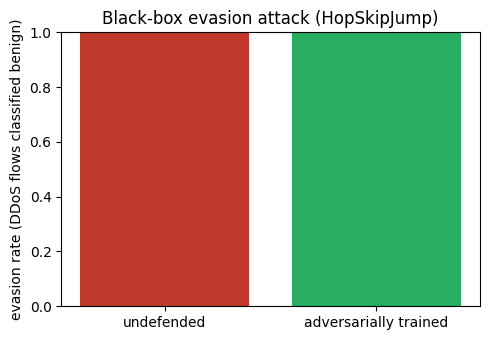

In [7]:
summary = pd.DataFrame([
    dict(model="undefended", clean_accuracy=base_acc, attack_recall=base_recall,
         evasion_rate=res_undef["evasion_rate"], median_l2=res_undef["median_l2"]),
    dict(model="adversarially trained", clean_accuracy=def_acc, attack_recall=def_recall,
         evasion_rate=res_def["evasion_rate"], median_l2=res_def["median_l2"]),
]).round(4)
summary.to_csv(RESULTS / "robustness_results.csv", index=False)
print(summary.to_string(index=False))
print("Old adversarial flows still evading defended model:", round(transfer, 3))

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(summary["model"], summary["evasion_rate"], color=["#c0392b", "#27ae60"])
ax.set_ylabel("evasion rate (DDoS flows classified benign)")
ax.set_ylim(0, 1)
ax.set_title("Black-box evasion attack (HopSkipJump)")
plt.tight_layout()
plt.savefig(RESULTS / "evasion_rate.png", dpi=150)
plt.show()

## 7. Limitations (state these in the write-up)
- **Simplified threat model:** perturbations stay inside the training feature ranges but ignore protocol constraints (integer counts, relations between features such as duration and packet counts). Some adversarial flows may not be physically realisable.
- **One day, two classes:** a single DDoS-vs-benign file is an easy problem. Results may not transfer to other attacks or datasets.
- **Small attack sample** (N_ATTACK flows) means wide uncertainty. Report it as indicative, not definitive.
- **Known dataset issues:** CIC-IDS-2017 has documented labelling and duplicate problems; de-duplication here is partial mitigation.
- Adversarial training was evaluated against the same attack family it was trained on; other attacks may still succeed.

 l2_budget  undefended  adversarially_trained
      0.05        0.04                   0.00
      0.10        0.05                   0.00
      0.20        0.76                   0.02
      0.30        0.85                   0.27
      0.40        0.86                   0.50
      0.60        0.86                   0.74
      1.00        0.97                   0.84


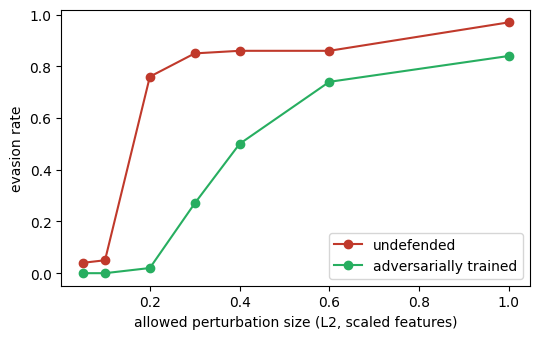

Fwd Packet Length Max          mean change 0.171
Destination Port               mean change 0.054
Fwd Packet Length Mean         mean change 0.041
Bwd Packets/s                  mean change 0.033
Total Length of Fwd Packets    mean change 0.028


In [8]:
budgets = [0.05, 0.1, 0.2, 0.3, 0.4, 0.6, 1.0]
Xd = Xte20[caught_def]
l2_u = np.linalg.norm(X_adv - X_atk, axis=1)
l2_d = np.linalg.norm(X_adv_def - Xd, axis=1)
ev_u = model.predict(X_adv) == 0
ev_d = model_def.predict(X_adv_def) == 0

budget_df = pd.DataFrame([dict(l2_budget=b,
        undefended=float(((l2_u <= b) & ev_u).mean()),
        adversarially_trained=float(((l2_d <= b) & ev_d).mean())) for b in budgets]).round(3)
budget_df.to_csv(RESULTS / "evasion_by_budget.csv", index=False)
print(budget_df.to_string(index=False))

plt.figure(figsize=(5.5, 3.5))
plt.plot(budget_df["l2_budget"], budget_df["undefended"], "o-", label="undefended", color="#c0392b")
plt.plot(budget_df["l2_budget"], budget_df["adversarially_trained"], "o-", label="adversarially trained", color="#27ae60")
plt.xlabel("allowed perturbation size (L2, scaled features)")
plt.ylabel("evasion rate")
plt.legend(); plt.tight_layout()
plt.savefig(RESULTS / "evasion_by_budget.png", dpi=150)
plt.show()

# which features did the attacker change most? (undefended)
delta = np.abs(X_adv - X_atk).mean(axis=0)
for i in np.argsort(delta)[::-1][:5]:
    print(f"{feat_names[i]:30s} mean change {delta[i]:.3f}")